<a href="https://colab.research.google.com/github/Kavin-Prakash-T/ds-sat-2/blob/main/CH13_DIGITAL_PAYMENT_INSIGHT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [56]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully")


Libraries imported successfully


In [57]:

transactions = pd.read_csv("transactions.csv")
customers = pd.read_csv("customers.csv")
devices = pd.read_csv("devices.csv")
merchants = pd.read_csv("merchants.csv")
alerts = pd.read_csv("alerts.csv")

print("Transactions:", transactions.shape)
print("Customers:", customers.shape)
print("Devices:", devices.shape)
print("Merchants:", merchants.shape)
print("Alerts:", alerts.shape)


Transactions: (5018, 11)
Customers: (650, 4)
Devices: (650, 5)
Merchants: (75, 3)
Alerts: (227, 4)


In [58]:

datasets = {
    "Transactions": transactions,
    "Customers": customers,
    "Devices": devices,
    "Merchants": merchants,
    "Alerts": alerts
}

for name, data in datasets.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    display(data.head())



Transactions
Shape: (5018, 11)
Columns: ['transaction_id', 'customer_id', 'merchant_id', 'time', 'amount', 'merchant_category', 'channel', 'region', 'device_id', 'new_device_flag', 'is_synthetic_anomaly']


,transaction_id,customer_id,merchant_id,time,amount,merchant_category,channel,region,device_id,new_device_flag,is_synthetic_anomaly
0,T004947,C0641,M001,2026-08-25 21:55:19,89.61,Transport,UPI,Coimbatore,D0641,0,0
1,T000557,C0625,M043,2026-09-24 17:25:47,1580.45,Entertainment,UPI,Coimbatore,D0625,0,0
2,T003226,C0322,M059,2026-09-20 04:02:14,477.60,Food & Dining,UPI,Coimbatore,D0322,0,0
3,T003505,C0022,M059,2026-08-28 22:11:11,5062.67,Food & Dining,UPI,Chennai,D0022,0,0
4,T000374,C0008,M053,2026-09-23 14:01:39,886.41,Travel,Web,Salem,D0008,0,0



Customers
Shape: (650, 4)
Columns: ['customer_id', 'customer_segment', 'region', 'tenure_months']


,customer_id,customer_segment,region,tenure_months
0,C0001,Affluent,Chennai,83.0
1,C0002,Affluent,Chennai,15.0
2,C0003,Affluent,Coimbatore,57.0
3,C0004,Mass,Coimbatore,16.0
4,C0005,Mass,Erode,44.0



Devices
Shape: (650, 5)
Columns: ['device_id', 'customer_id', 'device_type', 'new_device_flag', 'device_history_complete']


,device_id,customer_id,device_type,new_device_flag,device_history_complete
0,D0001,C0001,Android,0,1
1,D0002,C0002,iOS,0,1
2,D0003,C0003,iOS,0,1
3,D0004,C0004,Android,0,1
4,D0005,C0005,Android,1,1



Merchants
Shape: (75, 3)
Columns: ['merchant_id', 'merchant_category', 'region']


,merchant_id,merchant_category,region
0,M001,Transport,Erode
1,M002,Food & Dining,Erode
2,M003,Transport,Tiruchirappalli
3,M004,Grocery,Tiruchirappalli
4,M005,Electronics,Madurai



Alerts
Shape: (227, 4)
Columns: ['alert_id', 'transaction_id', 'review_status', 'reason_category']


,alert_id,transaction_id,review_status,reason_category
0,A00001,T000019,Pending,NaN
1,A00002,T000024,Escalated,Unusual Hour
2,A00003,T000040,Pending,Regional Spike
3,A00004,T000047,Escalated,New Device
4,A00005,T000110,Pending,Merchant Pattern


In [59]:

print("TRANSACTION DATA TYPES")
display(transactions.dtypes.rename("Data Type").to_frame())

print("\nNUMERICAL SUMMARY")
display(transactions.describe())

print("\nCATEGORICAL SUMMARY")
display(transactions.describe(include="object"))


TRANSACTION DATA TYPES


,Data Type
transaction_id,object
customer_id,object
merchant_id,object
time,object
amount,float64
merchant_category,object
channel,object
region,object
device_id,object
new_device_flag,int64



NUMERICAL SUMMARY


,amount,new_device_flag,is_synthetic_anomaly
count,5.018000e+03,5018.000000,5018.000000
mean,2.910867e+03,0.117577,0.035472
std,2.500484e+04,0.322138,0.184989
min,6.504000e+01,0.000000,0.000000
25%,5.002975e+02,0.000000,0.000000
50%,9.594100e+02,0.000000,0.000000
75%,2.247227e+03,0.000000,0.000000
max,1.166432e+06,1.000000,1.000000



CATEGORICAL SUMMARY


,transaction_id,customer_id,merchant_id,time,merchant_category,channel,region,device_id
count,5018,5018,5018,5018,4893,5018,5018,4772
unique,5000,650,75,5012,9,8,6,649
top,T003894,C0237,M037,2026-09-11 21:15:19,Electronics,UPI,Coimbatore,D0237
freq,2,20,92,2,820,2308,1259,20


In [60]:

tx = transactions.copy()

# Standardize column names
tx.columns = tx.columns.str.strip().str.lower()

# Remove rows without a transaction ID
tx = tx.dropna(subset=["transaction_id"])

# Remove duplicate transaction IDs, keeping the first record
tx = tx.drop_duplicates(subset=["transaction_id"], keep="first")

# Standardize channel labels
if "channel" in tx.columns:
    tx["channel"] = (
        tx["channel"]
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"[\s_-]+", "_", regex=True)
    )

# Convert timestamp to datetime if present
if "timestamp" in tx.columns:
    tx["timestamp"] = pd.to_datetime(tx["timestamp"], errors="coerce")
elif "transaction_time" in tx.columns:
    tx["transaction_time"] = pd.to_datetime(
        tx["transaction_time"], errors="coerce"
    )
elif "transaction_date" in tx.columns:
    tx["transaction_date"] = pd.to_datetime(
        tx["transaction_date"], errors="coerce"
    )

# Convert amount to numeric
tx["amount"] = pd.to_numeric(tx["amount"], errors="coerce")

print("Rows after duplicate removal:", len(tx))
print("Remaining duplicate IDs:", tx["transaction_id"].duplicated().sum())
print("Missing values after initial cleaning:")
display(tx.isnull().sum())


Rows after duplicate removal: 5000
Remaining duplicate IDs: 0
Missing values after initial cleaning:


,0
transaction_id,0
customer_id,0
merchant_id,0
time,0
amount,0
merchant_category,125
channel,0
region,0
device_id,245
new_device_flag,0


In [61]:

merchant_lookup = merchants.copy()
merchant_lookup.columns = merchant_lookup.columns.str.strip().str.lower()

if (
    "merchant_id" in tx.columns
    and "merchant_id" in merchant_lookup.columns
    and "merchant_category" in tx.columns
    and "category" in merchant_lookup.columns
):
    category_map = (
        merchant_lookup.dropna(subset=["merchant_id"])
        .drop_duplicates("merchant_id")
        .set_index("merchant_id")["category"]
    )

    missing_category = tx["merchant_category"].isna()
    tx.loc[missing_category, "merchant_category"] = (
        tx.loc[missing_category, "merchant_id"].map(category_map)
    )

if "merchant_category" in tx.columns:
    tx["merchant_category"] = (
        tx["merchant_category"].fillna("Unknown").astype(str).str.strip()
    )

print("Remaining missing merchant categories:",
      tx["merchant_category"].isna().sum()
      if "merchant_category" in tx.columns else "Column unavailable")

if "merchant_category" in tx.columns:
    print("\nMerchant category counts:")
    display(tx["merchant_category"].value_counts())


Remaining missing merchant categories: 0

Merchant category counts:


,count
merchant_category,
Electronics,818
Food & Dining,811
Fashion,600
Transport,591
Entertainment,530
Grocery,517
Healthcare,352
Utilities,343
Travel,313


In [62]:

# IQR-based flag; this identifies potential outliers without deleting them
q1 = tx["amount"].quantile(0.25)
q3 = tx["amount"].quantile(0.75)
iqr = q3 - q1

lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

tx["extreme_amount_flag"] = (
    (tx["amount"] < lower_bound) |
    (tx["amount"] > upper_bound)
).astype(int)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential extreme amounts:", tx["extreme_amount_flag"].sum())

display(
    tx.loc[tx["extreme_amount_flag"] == 1, ["transaction_id", "amount"]]
    .head(10)
)


Lower bound: 0
Upper bound: 4882.1825
Potential extreme amounts: 472


,transaction_id,amount
3,T003505,5062.67
32,T001953,7322.71
53,T001260,6295.82
66,T000733,10984.89
83,T000028,7543.31
95,T001829,4915.60
101,T002078,16488.77
120,T001567,6973.81
139,T003992,5443.79
150,T001382,5666.85


In [63]:

def normalize_columns(data):
    data = data.copy()
    data.columns = data.columns.str.strip().str.lower()
    return data

cust = normalize_columns(customers)
dev = normalize_columns(devices)
merch = normalize_columns(merchants)
al = normalize_columns(alerts)

df = tx.copy()

# Merge customer information
if "customer_id" in df.columns and "customer_id" in cust.columns:
    if "customer_id" in cust.columns:
        cust = cust.drop_duplicates("customer_id")
    customer_cols = [
        c for c in cust.columns
        if c == "customer_id" or c not in df.columns
    ]
    df = df.merge(cust[customer_cols], on="customer_id", how="left")

# Merge device information when a transaction-level key exists
device_key = next(
    (k for k in ["transaction_id", "device_id", "customer_id"]
     if k in df.columns and k in dev.columns),
    None
)

if device_key:
    if device_key == "transaction_id":
        dev = dev.drop_duplicates(device_key)
    elif device_key == "device_id":
        dev = dev.drop_duplicates(device_key)

    device_cols = [
        c for c in dev.columns
        if c == device_key or c not in df.columns
    ]
    df = df.merge(dev[device_cols], on=device_key, how="left")

# Merge merchant lookup only when merchant ID exists
if "merchant_id" in df.columns and "merchant_id" in merch.columns:
    merch = merch.drop_duplicates("merchant_id")
    merchant_cols = [
        c for c in merch.columns
        if c == "merchant_id" or c not in df.columns
    ]
    df = df.merge(merch[merchant_cols], on="merchant_id", how="left")

# Create a target from alert records
if "transaction_id" in al.columns:
    al["has_alert"] = 1
    alert_ids = al[["transaction_id", "has_alert"]].drop_duplicates(
        "transaction_id"
    )
    df = df.merge(alert_ids, on="transaction_id", how="left")
    df["has_alert"] = df["has_alert"].fillna(0).astype(int)

print("Merged dataset shape:", df.shape)
display(df.head())


Merged dataset shape: (5000, 17)


,transaction_id,customer_id,merchant_id,time,amount,merchant_category,channel,region,device_id,new_device_flag,is_synthetic_anomaly,extreme_amount_flag,customer_segment,tenure_months,device_type,device_history_complete,has_alert
0,T004947,C0641,M001,2026-08-25 21:55:19,89.61,Transport,upi,Coimbatore,D0641,0,0,0,Mass,26.0,Web,1.0,0
1,T000557,C0625,M043,2026-09-24 17:25:47,1580.45,Entertainment,upi,Coimbatore,D0625,0,0,0,Emerging,42.0,Android,1.0,0
2,T003226,C0322,M059,2026-09-20 04:02:14,477.60,Food & Dining,upi,Coimbatore,D0322,0,0,0,Mass,95.0,Android,1.0,0
3,T003505,C0022,M059,2026-08-28 22:11:11,5062.67,Food & Dining,upi,Chennai,D0022,0,0,1,Affluent,23.0,POS,1.0,0
4,T000374,C0008,M053,2026-09-23 14:01:39,886.41,Travel,web,Salem,D0008,0,0,0,Mass,29.0,Web,1.0,0


In [64]:

time_col = next(
    (c for c in ["timestamp", "transaction_time", "transaction_date"]
     if c in df.columns),
    None
)

if time_col:
    df[time_col] = pd.to_datetime(df[time_col], errors="coerce")
    df["hour"] = df[time_col].dt.hour
    df["day_of_week"] = df[time_col].dt.day_name()
    df["month"] = df[time_col].dt.month
else:
    print("No recognized transaction time column found.")

if "amount" in df.columns:
    df["amount_log"] = np.log1p(df["amount"].clip(lower=0))

display(df.head())


No recognized transaction time column found.


,transaction_id,customer_id,merchant_id,time,amount,merchant_category,channel,region,device_id,new_device_flag,is_synthetic_anomaly,extreme_amount_flag,customer_segment,tenure_months,device_type,device_history_complete,has_alert,amount_log
0,T004947,C0641,M001,2026-08-25 21:55:19,89.61,Transport,upi,Coimbatore,D0641,0,0,0,Mass,26.0,Web,1.0,0,4.506565
1,T000557,C0625,M043,2026-09-24 17:25:47,1580.45,Entertainment,upi,Coimbatore,D0625,0,0,0,Emerging,42.0,Android,1.0,0,7.366097
2,T003226,C0322,M059,2026-09-20 04:02:14,477.60,Food & Dining,upi,Coimbatore,D0322,0,0,0,Mass,95.0,Android,1.0,0,6.170865
3,T003505,C0022,M059,2026-08-28 22:11:11,5062.67,Food & Dining,upi,Chennai,D0022,0,0,1,Affluent,23.0,POS,1.0,0,8.529847
4,T000374,C0008,M053,2026-09-23 14:01:39,886.41,Travel,web,Salem,D0008,0,0,0,Mass,29.0,Web,1.0,0,6.788307


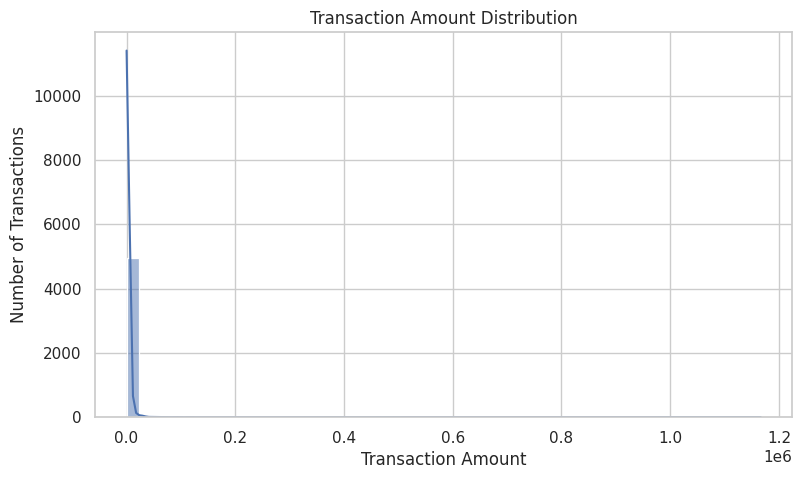

In [65]:

plt.figure(figsize=(9, 5))
sns.histplot(df["amount"].dropna(), bins=50, kde=True)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()


In [66]:

if "hour" in df.columns:
    hourly = df.groupby("hour").size()

    plt.figure(figsize=(10, 5))
    hourly.plot(kind="bar")
    plt.title("Transaction Volume by Hour")
    plt.xlabel("Hour of Day")
    plt.ylabel("Number of Transactions")
    plt.xticks(rotation=0)
    plt.show()

    display(hourly.sort_values(ascending=False).head(10))


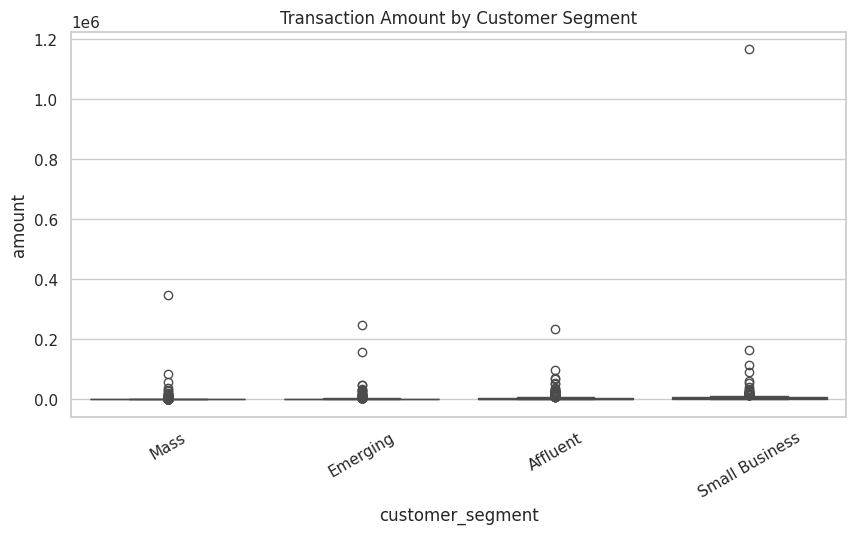

,amount
customer_segment,
Small Business,4239.18
Affluent,2759.76
Emerging,1090.32
Mass,538.65


In [47]:

segment_col = next(
    (c for c in ["customer_segment", "segment"]
     if c in df.columns),
    None
)

if segment_col:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x=segment_col, y="amount")
    plt.title("Transaction Amount by Customer Segment")
    plt.xticks(rotation=30)
    plt.show()

    display(df.groupby(segment_col)["amount"].median().sort_values(
        ascending=False
    ))
else:
    print("Customer segment column not found.")


,transactions,alert_count,alert_rate,alert_rate_pct
new_device_flag,,,,
0,4411,176,0.039900,3.990025
1,589,51,0.086587,8.658744


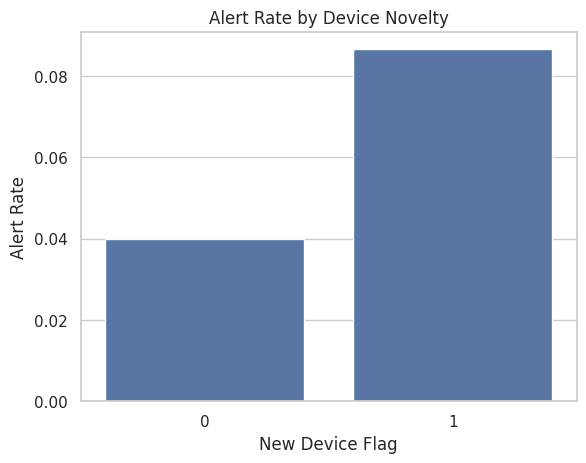

In [48]:

new_device_col = next(
    (c for c in ["new_device_flag", "is_new_device"]
     if c in df.columns),
    None
)

if new_device_col and "has_alert" in df.columns:
    device_alerts = df.groupby(new_device_col)["has_alert"].agg(
        transactions="count",
        alert_count="sum",
        alert_rate="mean"
    )

    device_alerts["alert_rate_pct"] = device_alerts["alert_rate"] * 100
    display(device_alerts)

    sns.barplot(
        data=df,
        x=new_device_col,
        y="has_alert",
        errorbar=None
    )
    plt.title("Alert Rate by Device Novelty")
    plt.xlabel("New Device Flag")
    plt.ylabel("Alert Rate")
    plt.show()
else:
    print("Device novelty or alert target is unavailable.")


,transactions,alerts,alert_rate,alert_rate_pct
merchant_category,,,,
Travel,313,22,0.070288,7.028754
Unknown,125,8,0.064000,6.400000
Electronics,818,50,0.061125,6.112469
Entertainment,530,29,0.054717,5.471698
Healthcare,352,16,0.045455,4.545455
Fashion,600,26,0.043333,4.333333
Utilities,343,13,0.037901,3.790087
Transport,591,22,0.037225,3.722504
Grocery,517,17,0.032882,3.288201


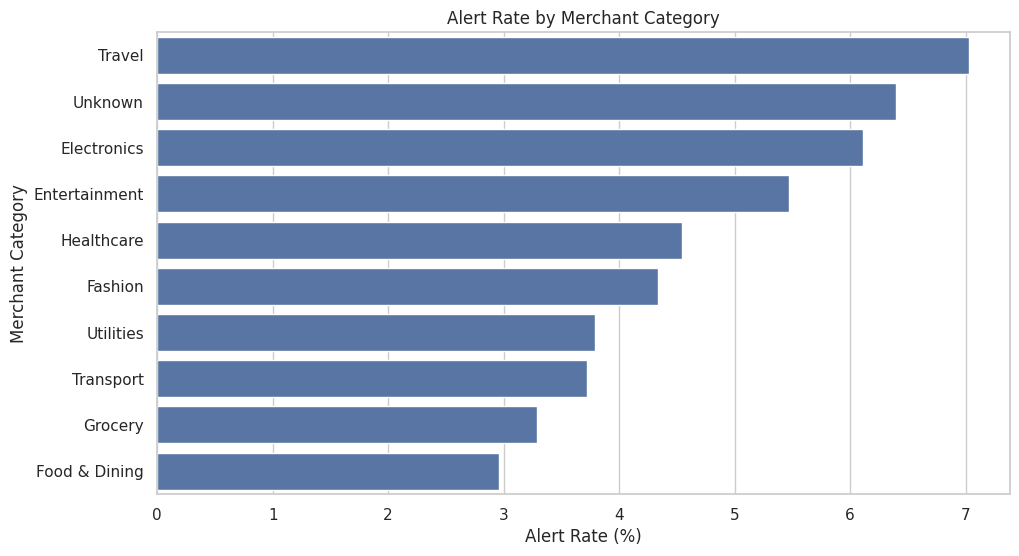

In [49]:

if "merchant_category" in df.columns and "has_alert" in df.columns:
    category_alerts = (
        df.groupby("merchant_category")["has_alert"]
        .agg(transactions="count", alerts="sum", alert_rate="mean")
        .sort_values("alert_rate", ascending=False)
    )

    category_alerts["alert_rate_pct"] = category_alerts["alert_rate"] * 100
    display(category_alerts)

    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=category_alerts.reset_index(),
        x="alert_rate_pct",
        y="merchant_category"
    )
    plt.title("Alert Rate by Merchant Category")
    plt.xlabel("Alert Rate (%)")
    plt.ylabel("Merchant Category")
    plt.show()


,transactions,alerts,alert_rate,alert_rate_pct
region,,,,
Coimbatore,1254,68,0.054226,5.422648
Erode,536,25,0.046642,4.664179
Chennai,1219,56,0.045939,4.593929
Tiruchirappalli,551,23,0.041742,4.174229
Madurai,726,29,0.039945,3.994490
Salem,714,26,0.036415,3.641457


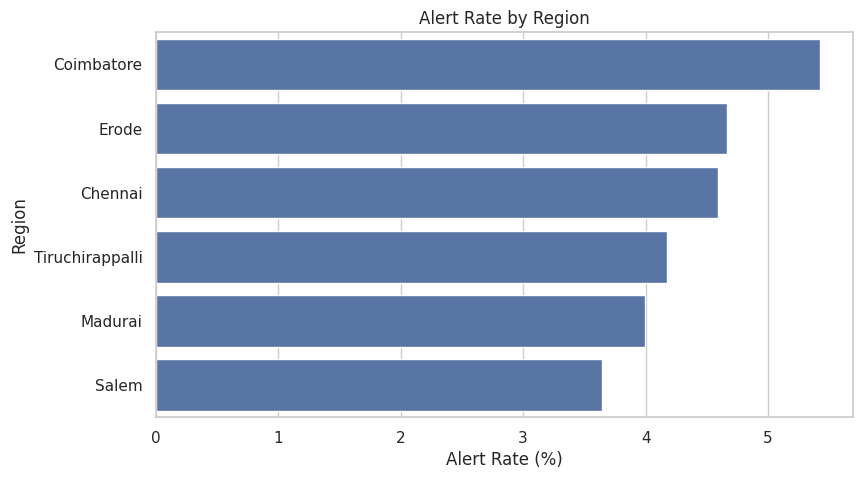

In [50]:

region_col = next(
    (c for c in ["region", "customer_region", "merchant_region"]
     if c in df.columns),
    None
)

if region_col and "has_alert" in df.columns:
    region_alerts = (
        df.groupby(region_col)["has_alert"]
        .agg(transactions="count", alerts="sum", alert_rate="mean")
        .sort_values("alert_rate", ascending=False)
    )

    region_alerts["alert_rate_pct"] = region_alerts["alert_rate"] * 100
    display(region_alerts)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=region_alerts.reset_index(),
        x="alert_rate_pct",
        y=region_col
    )
    plt.title("Alert Rate by Region")
    plt.xlabel("Alert Rate (%)")
    plt.ylabel("Region")
    plt.show()
else:
    print("Region or alert target is unavailable.")


In [51]:

target = "has_alert"

candidate_features = [
    "amount",
    "hour",
    "new_device_flag",
    "is_new_device",
    "merchant_category",
    "channel",
    "region",
    "customer_segment",
    "segment",
    "device_type",
    "tenure_months",
    "extreme_amount_flag"
]

features = [c for c in candidate_features if c in df.columns]

if target not in df.columns:
    raise ValueError(
        "Alert target was not created. Check the alert merge and transaction IDs."
    )

if not features:
    raise ValueError("No usable model features were found.")

model_data = df[features + [target]].copy()
model_data = model_data.dropna(subset=[target])

X = model_data[features]
y = model_data[target].astype(int)

print("Selected features:", features)
print("\nTarget distribution:")
display(y.value_counts().rename("count").to_frame())
print("\nTarget percentages:")
display((y.value_counts(normalize=True) * 100).round(2))


Selected features: ['amount', 'new_device_flag', 'merchant_category', 'channel', 'region', 'customer_segment', 'device_type', 'tenure_months', 'extreme_amount_flag']

Target distribution:


,count
has_alert,
0,4773
1,227



Target percentages:


,proportion
has_alert,
0,95.46
1,4.54


In [52]:

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        max_depth=10
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Model training completed.")


Model training completed.


Accuracy : 0.9490
Precision: 0.0000
Recall   : 0.0000
F1-score : 0.0000

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       955
           1       0.00      0.00      0.00        45

    accuracy                           0.95      1000
   macro avg       0.48      0.50      0.49      1000
weighted avg       0.91      0.95      0.93      1000


Confusion Matrix:
[[949   6]
 [ 45   0]]


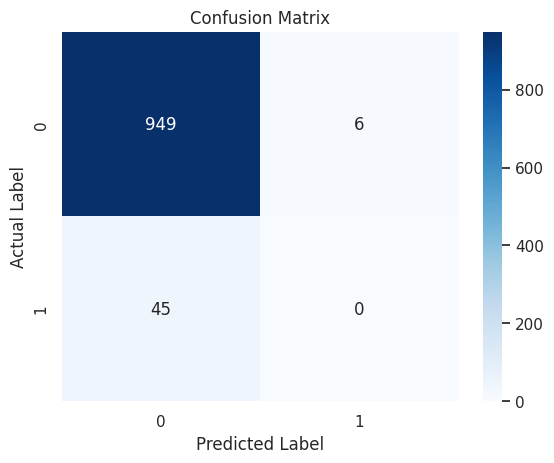

ROC-AUC: 0.5412


In [53]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

if len(np.unique(y_test)) == 2:
    y_prob = model.predict_proba(X_test)[:, 1]
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))


In [54]:

print("KEY BUSINESS FINDINGS")
print("=" * 50)

print("\n1. Transaction amount:")
print("Median amount:", round(df["amount"].median(), 2))
print("Maximum amount:", round(df["amount"].max(), 2))
print("Potential extreme amounts:", int(df["extreme_amount_flag"].sum()))

if segment_col:
    print("\n2. Median transaction amount by segment:")
    display(df.groupby(segment_col)["amount"].median().sort_values(
        ascending=False
    ))

if new_device_col and "has_alert" in df.columns:
    print("\n3. Alert rate by device novelty:")
    display(
        (df.groupby(new_device_col)["has_alert"].mean() * 100)
        .round(2)
        .rename("Alert Rate (%)")
    )

if "merchant_category" in df.columns and "has_alert" in df.columns:
    print("\n4. Categories with the highest alert rates:")
    display(
        (df.groupby("merchant_category")["has_alert"].mean() * 100)
        .sort_values(ascending=False)
        .head(5)
        .round(2)
        .rename("Alert Rate (%)")
    )

if region_col and "has_alert" in df.columns:
    print("\n5. Regions with the highest alert rates:")
    display(
        (df.groupby(region_col)["has_alert"].mean() * 100)
        .sort_values(ascending=False)
        .round(2)
        .rename("Alert Rate (%)")
    )


KEY BUSINESS FINDINGS

1. Transaction amount:
Median amount: 959.26
Maximum amount: 1166432.0
Potential extreme amounts: 472

2. Median transaction amount by segment:


,amount
customer_segment,
Small Business,4239.18
Affluent,2759.76
Emerging,1090.32
Mass,538.65



3. Alert rate by device novelty:


,Alert Rate (%)
new_device_flag,
0,3.99
1,8.66



4. Categories with the highest alert rates:


,Alert Rate (%)
merchant_category,
Travel,7.03
Unknown,6.40
Electronics,6.11
Entertainment,5.47
Healthcare,4.55



5. Regions with the highest alert rates:


,Alert Rate (%)
region,
Coimbatore,5.42
Erode,4.66
Chennai,4.59
Tiruchirappalli,4.17
Madurai,3.99
Salem,3.64


In [67]:

print("Training target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nPredicted target distribution:")
print(pd.Series(y_pred).value_counts())


Training target distribution:
has_alert
0    3818
1     182
Name: count, dtype: int64

Test target distribution:
has_alert
0    955
1     45
Name: count, dtype: int64

Predicted target distribution:
0    994
1      6
Name: count, dtype: int64


In [68]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.utils import resample

# Combine training features and labels
train_data = X_train.copy()
train_data["_target"] = y_train.values

# Separate the two classes
majority = train_data[train_data["_target"] == 0]
minority = train_data[train_data["_target"] == 1]

print("No Alert records:", len(majority))
print("Alert records:", len(minority))

if len(minority) == 0:
    raise ValueError("No positive alert examples in the training data.")

# Oversample the minority class using training data only
minority_oversampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

balanced_train = pd.concat(
    [majority, minority_oversampled],
    ignore_index=True
).sample(frac=1, random_state=42)

X_train_balanced = balanced_train[features]
y_train_balanced = balanced_train["_target"].astype(int)

# Build a new model with the existing preprocessing pipeline
improved_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42
    ))
])

improved_model.fit(X_train_balanced, y_train_balanced)

# Predict on the original, untouched test set
y_pred_improved = improved_model.predict(X_test)

print("\nIMPROVED MODEL RESULTS")
print("Accuracy:",
      round(accuracy_score(y_test, y_pred_improved), 4))
print("Precision:",
      round(precision_score(y_test, y_pred_improved, zero_division=0), 4))
print("Recall:",
      round(recall_score(y_test, y_pred_improved, zero_division=0), 4))
print("F1-score:",
      round(f1_score(y_test, y_pred_improved, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_improved, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_improved))


No Alert records: 3818
Alert records: 182

IMPROVED MODEL RESULTS
Accuracy: 0.92
Precision: 0.0513
Recall: 0.0444
F1-score: 0.0476

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       955
           1       0.05      0.04      0.05        45

    accuracy                           0.92      1000
   macro avg       0.50      0.50      0.50      1000
weighted avg       0.91      0.92      0.92      1000

Confusion Matrix:
[[918  37]
 [ 43   2]]


In [69]:

from google.colab import files

df.to_csv("cleaned_payment_transactions.csv", index=False)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [accuracy, precision, recall, f1]
})
metrics.to_csv("model_evaluation_metrics.csv", index=False)

print("Files saved:")
print("1. cleaned_payment_transactions.csv")
print("2. model_evaluation_metrics.csv")

files.download("cleaned_payment_transactions.csv")
files.download("model_evaluation_metrics.csv")


Files saved:
1. cleaned_payment_transactions.csv
2. model_evaluation_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>